# Atividade Prática 4: Classificação de imagens com Deep Learning
### Nome: Victor Hugo Oliveira da Silva nUSP: 11320901
### Prof. Dr. Fabio Lobato

Para esse trabalho eu vou utilizar o dataset Fashion-MNIST. O Fashion-MNIST é um dataset da Zalando, consistindo em um conjunto de 60mil exemplos e um conjunto de teste de 10mil exemplos. Cada exemplo de 28x28 em escala de cinza, associado com um *label* de 10 classes. O dataset contempla um conjunto de vestimentas, dividido nas seguintes classes:

| **Label** | **Description**|
| --- | --- |
| 0 | T-shirt/top |
| 1 | Trouser |
| 2 | Pullover |
| 3 | Dress |
| 4 | Coat |
| 5 | Sandal |
| 6 | Shirt |
| 7 | Sneaker |
| 8 | Bag |
| 9 | Ankle boot |


É possivel baixar o dataset diretamente nos seguintes links:

| **Name**  | **Content** | **Examples** | **Size** | **Link** | **MD5 Checksum**|
| --- | --- |--- | --- |--- |--- |
| `train-images-idx3-ubyte.gz`  | training set images  | 60,000|26 MBytes | [Download](https://github.com/zalandoresearch/fashion-mnist/blob/master/data/fashion/train-images-idx3-ubyte.gz)|`8d4fb7e6c68d591d4c3dfef9ec88bf0d`|
| `train-labels-idx1-ubyte.gz`  | training set labels  |60,000|29 KBytes | [Download](https://github.com/zalandoresearch/fashion-mnist/blob/master/data/fashion/train-labels-idx1-ubyte.gz)|`25c81989df183df01b3e8a0aad5dffbe`|
| `t10k-images-idx3-ubyte.gz`  | test set images  | 10,000|4.3 MBytes | [Download](https://github.com/zalandoresearch/fashion-mnist/blob/master/data/fashion/t10k-images-idx3-ubyte.gz)|`bef4ecab320f06d8554ea6380940ec79`|
| `t10k-labels-idx1-ubyte.gz`  | test set labels  | 10,000| 5.1 KBytes | [Download](https://github.com/zalandoresearch/fashion-mnist/blob/master/data/fashion/t10k-labels-idx1-ubyte.gz)|`bb300cfdad3c16e7a12a480ee83cd310`|

Vou comparar uma regressão logística (baseline) com três redes pré-treinadas no ImageNet: ResNet-50, ConvNeXt-Tiny e ViT-Small/16.

In [1]:
!pip install -q -U timm

In [2]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
from torch.utils.data import TensorDataset, DataLoader
from torchvision.transforms import Normalize
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# caminhos dataset
DATA_BASEPATH = "/kaggle/input/datasets/otorugo/t4-fashion-mnist"

SEED = 42
IMG_SIZE = 112
BATCH_SIZE = 128
EPOCHS = 5
LR = 1e-4
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = DEVICE.type == "cuda"

def fixar_seed():
    np.random.seed(SEED)
    torch.manual_seed(SEED)

fixar_seed()
print(DEVICE, torch.cuda.get_device_name(0) if AMP else "")

cuda Tesla T4


o trecho abaixo foi retirado do github do dataset, um código auxiliar para leitura do mesmo
pode ser encontrado em https://github.com/zalandoresearch/fashion-mnist/blob/master/utils/mnist_reader.py

In [3]:
def load_mnist(path, kind='train'):
    """Load MNIST data from `path`"""
    labels_path = os.path.join(path,
                               '%s-labels-idx1-ubyte'
                               % kind)
    images_path = os.path.join(path,
                               '%s-images-idx3-ubyte'
                               % kind)
    print(images_path)
    with open(labels_path, 'rb') as lbpath:
        labels = np.frombuffer(lbpath.read(), dtype=np.uint8,
                               offset=8)

    with open(images_path, 'rb') as imgpath:
        images = np.frombuffer(imgpath.read(), dtype=np.uint8,
                               offset=16).reshape(len(labels), 784)
        images = images.reshape(-1,28,28)

    return images, labels

Leitura dos conjuntos de treino e teste

In [4]:
X_train, y_train = load_mnist(DATA_BASEPATH, kind='train')
X_test, y_test = load_mnist(DATA_BASEPATH, kind='t10k')

def conferir(nome, X, y):
    print(f"{nome}: imagens {X.shape} {X.dtype} [{X.min()}, {X.max()}] | labels {y.shape} classes {np.unique(y)}")

conferir("Treino", X_train, y_train)
conferir("Teste", X_test, y_test)

/kaggle/input/datasets/otorugo/t4-fashion-mnist/train-images-idx3-ubyte
/kaggle/input/datasets/otorugo/t4-fashion-mnist/t10k-images-idx3-ubyte
Treino: imagens (60000, 28, 28) uint8 [0, 255] | labels (60000,) classes [0 1 2 3 4 5 6 7 8 9]
Teste: imagens (10000, 28, 28) uint8 [0, 255] | labels (10000,) classes [0 1 2 3 4 5 6 7 8 9]


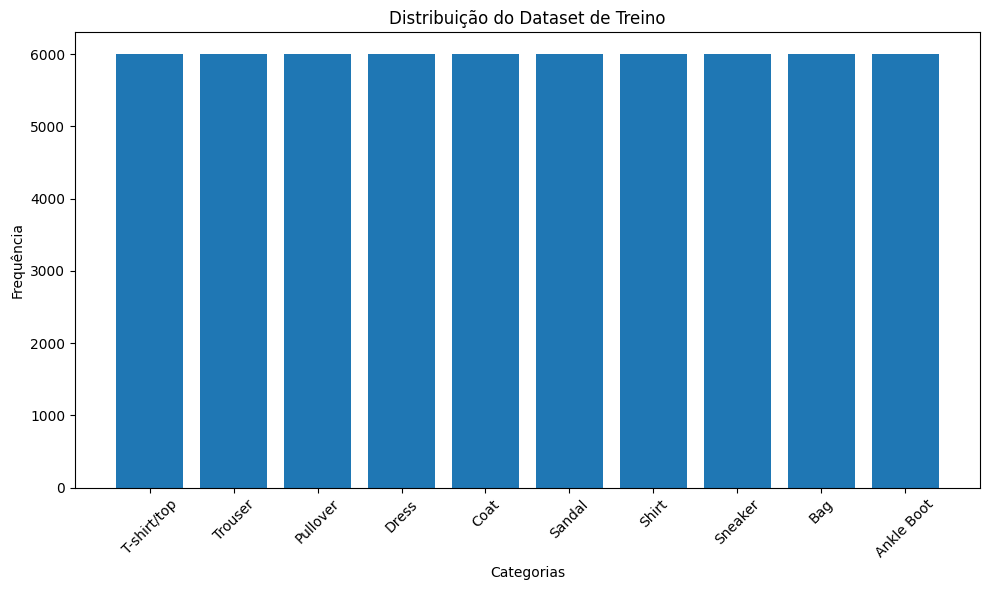

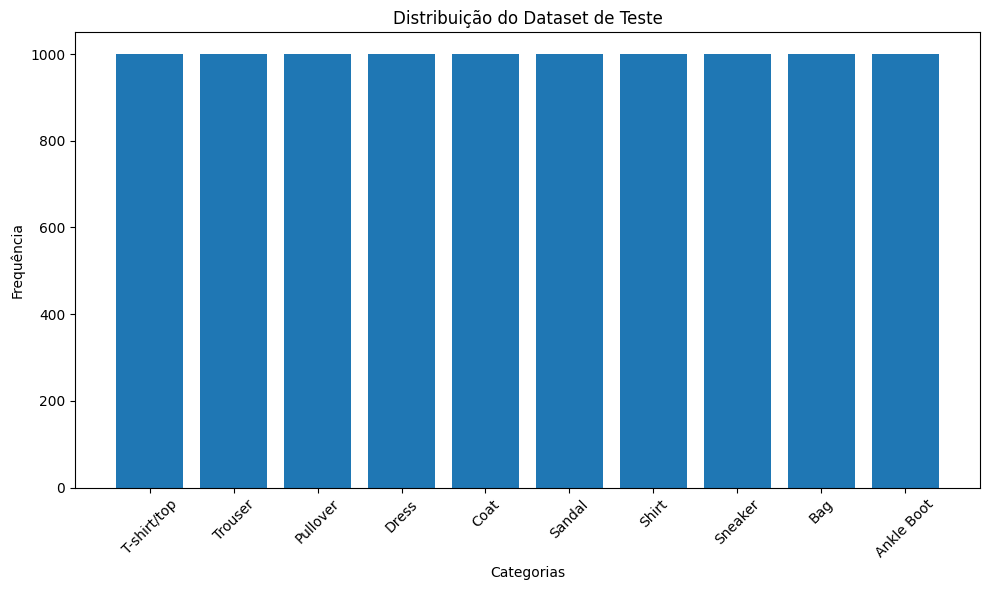

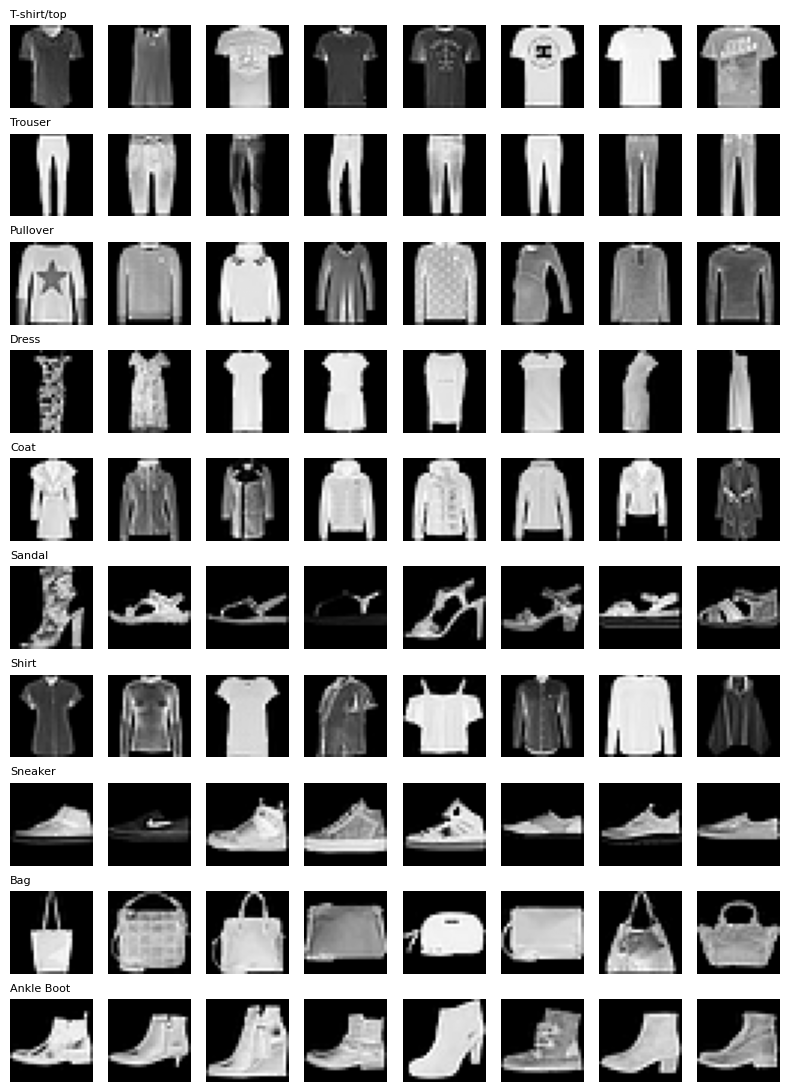

In [5]:
labels = {0 : "T-shirt/top", 1: "Trouser", 2: "Pullover", 3: "Dress", 4: "Coat",
          5: "Sandal", 6: "Shirt", 7: "Sneaker", 8: "Bag", 9: "Ankle Boot"}
CLASSES = list(labels.values())

def distribuition_dataset(categorias,feq,titulo):
    fig, ax = plt.subplots(figsize=(10,6))
    ax.bar(categorias,feq)
    ax.set_title(titulo)
    ax.set_xlabel("Categorias")
    ax.set_ylabel("Frequência")
    ax.tick_params(axis="x",rotation=45)
    fig.tight_layout()
    plt.show()

distribuition_dataset(CLASSES, np.bincount(y_train), "Distribuição do Dataset de Treino")
distribuition_dataset(CLASSES, np.bincount(y_test), "Distribuição do Dataset de Teste")

fig, axes = plt.subplots(10, 8, figsize=(8, 11))
for c in range(10):
    idx = np.random.choice(np.where(y_train == c)[0], 8, replace=False)
    for j, i in enumerate(idx):
        axes[c, j].imshow(X_train[i], cmap="gray"); axes[c, j].axis("off")
    axes[c, 0].set_title(labels[c], loc="left", fontsize=8)
plt.tight_layout(); plt.show()

Podemos ver que o dataset está bem distribuido com relação as suas quantidades por classe. Por isso a acurácia é uma boa métrica aqui, mas também vou olhar o F1 macro e o recall por classe.

Nos exemplos dá para ver dois grupos parecidos: roupas de cima (T-shirt/top, Pullover, Coat e Shirt) e calçados (Sandal, Sneaker e Ankle Boot). É onde os modelos devem errar mais.

## Divisão em treino e validação

O teste fica separado até o final. Do treino, tiro 10% para validação (estratificado), que vai servir para escolher a melhor época de cada modelo.

In [6]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.1, stratify=y_train, random_state=SEED)

conferir("Treino", X_tr, y_tr)
conferir("Validação", X_val, y_val)
print("por classe:", np.bincount(y_tr), np.bincount(y_val))

Treino: imagens (54000, 28, 28) uint8 [0, 255] | labels (54000,) classes [0 1 2 3 4 5 6 7 8 9]
Validação: imagens (6000, 28, 28) uint8 [0, 255] | labels (6000,) classes [0 1 2 3 4 5 6 7 8 9]
por classe: [5400 5400 5400 5400 5400 5400 5400 5400 5400 5400] [600 600 600 600 600 600 600 600 600 600]


## Baseline: Regressão Logística

Antes das redes, um modelo simples direto nos pixels (784 valores entre 0 e 1), para ter uma referência do que a deep learning ganha.

In [7]:
def achatar(X):
    return X.reshape(len(X), -1) / 255

t0 = time.time()
baseline = LogisticRegression(max_iter=500)
baseline.fit(achatar(X_tr), y_tr)
tempo_baseline = (time.time() - t0) / 60
acc_val_baseline = baseline.score(achatar(X_val), y_val)
print(f"Regressão Logística: acc validação {acc_val_baseline:.4f} | treino {tempo_baseline:.1f} min")

Regressão Logística: acc validação 0.8608 | treino 1.6 min


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Pré-processamento

Os modelos foram pré-treinados com imagens coloridas 224x224, então cada batch passa por: pixels para [0, 1], flip horizontal aleatório (só no treino), resize para 112x112 e cópia do canal cinza para 3 canais. Isso é feito na GPU, que é bem mais rápida que a CPU do Kaggle.

In [8]:
def criar_loader(X, y, shuffle):
    ds = TensorDataset(torch.tensor(np.array(X)).unsqueeze(1), torch.tensor(np.array(y)).long())
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=2,
                      generator=torch.Generator().manual_seed(SEED))

def preparar_batch(x, treino):
    x = x.to(DEVICE).float() / 255
    if treino:
        flip = torch.rand(len(x), 1, 1, 1, device=DEVICE) < 0.5
        x = torch.where(flip, x.flip(3), x)
    x = F.interpolate(x, size=IMG_SIZE, mode="bilinear")
    return x.repeat(1, 3, 1, 1)

train_loader = criar_loader(X_tr, y_tr, shuffle=True)
val_loader = criar_loader(X_val, y_val, shuffle=False)
test_loader = criar_loader(X_test, y_test, shuffle=False)

x, y = next(iter(train_loader))
xb = preparar_batch(x, treino=True)
print(tuple(x.shape), "->", tuple(xb.shape), f"| média {xb.mean():.3f} desvio {xb.std():.3f}")

(128, 1, 28, 28) -> (128, 3, 112, 112) | média 0.283 desvio 0.335


## Modelos

Os três vêm da `timm`, com pesos treinados só no ImageNet-1k:

- **ResNet-50**: CNN clássica com conexões residuais.
- **ConvNeXt-Tiny**: CNN moderna, redesenhada com ideias dos Transformers.
- **ViT-Small/16**: Transformer, divide a imagem em patches de 16x16 (com 112x112 são 49 patches).

A última camada é trocada por uma de 10 saídas. Cada modelo também recebe a normalização (média e desvio) usada no seu pré-treino.

In [9]:
MODELOS = {
    "ResNet-50": "resnet50.a1_in1k",
    "ConvNeXt-Tiny": "convnext_tiny.fb_in1k",
    "ViT-Small/16": "vit_small_patch16_224.augreg_in1k",
}

def criar_modelo(nome_timm):
    extra = {"img_size": IMG_SIZE} if "vit" in nome_timm else {}
    modelo = timm.create_model(nome_timm, pretrained=True, num_classes=10, **extra)
    cfg = modelo.pretrained_cfg
    return nn.Sequential(Normalize(cfg["mean"], cfg["std"]), modelo)

## Treinamento

Mesmo protocolo para os três: fine-tuning de todas as camadas, AdamW (lr 1e-4, weight decay 0.05), OneCycle, 5 épocas e precisão mista (float16). No fim de cada época avalio na validação e guardo o melhor checkpoint.

In [10]:
criterio = nn.CrossEntropyLoss()

def treinar_epoca(modelo, otimizador, agendador, scaler):
    modelo.train()
    soma_loss, acertos = 0, 0
    for x, y in train_loader:
        x, y = preparar_batch(x, treino=True), y.to(DEVICE)
        otimizador.zero_grad()
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
            saida = modelo(x)
            loss = criterio(saida, y)
        scaler.scale(loss).backward()
        scaler.step(otimizador)
        scaler.update()
        agendador.step()
        soma_loss += loss.item() * len(y)
        acertos += (saida.argmax(1) == y).sum().item()
    n = len(train_loader.dataset)
    return soma_loss / n, acertos / n

@torch.no_grad()
def avaliar(modelo, loader):
    modelo.eval()
    soma_loss, preds = 0, []
    for x, y in loader:
        x, y = preparar_batch(x, treino=False), y.to(DEVICE)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
            saida = modelo(x)
            soma_loss += criterio(saida, y).item() * len(y)
        preds.append(saida.argmax(1).cpu())
    preds = torch.cat(preds).numpy()
    rotulos = loader.dataset.tensors[1].numpy()
    return soma_loss / len(rotulos), (preds == rotulos).mean(), preds

modelos, historicos, infos = {}, {}, {}

def treinar_modelo(nome):
    fixar_seed()
    modelo = criar_modelo(MODELOS[nome]).to(DEVICE)
    otimizador = torch.optim.AdamW(modelo.parameters(), lr=LR, weight_decay=0.05)
    agendador = torch.optim.lr_scheduler.OneCycleLR(otimizador, max_lr=LR, total_steps=EPOCHS * len(train_loader), pct_start=0.1)
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=AMP)
    arquivo = MODELOS[nome] + ".pt"

    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    melhor = 0
    inicio = time.time()
    for ep in range(1, EPOCHS + 1):
        t0 = time.time()
        tl, ta = treinar_epoca(modelo, otimizador, agendador, scaler)
        vl, va, _ = avaliar(modelo, val_loader)
        for k, v in zip(hist, (tl, ta, vl, va)):
            hist[k].append(v)
        print(f"[{nome}] época {ep}/{EPOCHS} | treino loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f} | {time.time() - t0:.0f}s")
        if va > melhor:
            melhor = va
            torch.save(modelo.state_dict(), arquivo)

    modelo.load_state_dict(torch.load(arquivo))
    modelos[nome] = modelo
    historicos[nome] = hist
    infos[nome] = {"params": sum(p.numel() for p in modelo.parameters()) / 1e6,
                   "tempo": (time.time() - inicio) / 60, "val_acc": melhor}
    print(f"{nome}: melhor acc validação {melhor:.4f} | {infos[nome]['tempo']:.1f} min")

In [11]:
treinar_modelo("ResNet-50")

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_22/3737301648.py:15: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  agendador.step()


[ResNet-50] época 1/5 | treino loss 1.2095 acc 0.6153 | val loss 0.4966 acc 0.8455 | 64s
[ResNet-50] época 2/5 | treino loss 0.2840 acc 0.8994 | val loss 0.2760 acc 0.9043 | 68s
[ResNet-50] época 3/5 | treino loss 0.2104 acc 0.9251 | val loss 0.2004 acc 0.9255 | 67s
[ResNet-50] época 4/5 | treino loss 0.1756 acc 0.9383 | val loss 0.1916 acc 0.9303 | 68s
[ResNet-50] época 5/5 | treino loss 0.1583 acc 0.9451 | val loss 0.1911 acc 0.9322 | 68s
ResNet-50: melhor acc validação 0.9322 | 5.6 min


In [12]:
treinar_modelo("ConvNeXt-Tiny")

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

[ConvNeXt-Tiny] época 1/5 | treino loss 0.6889 acc 0.7966 | val loss 0.1818 acc 0.9327 | 96s
[ConvNeXt-Tiny] época 2/5 | treino loss 0.1589 acc 0.9452 | val loss 0.1395 acc 0.9485 | 72s
[ConvNeXt-Tiny] época 3/5 | treino loss 0.1094 acc 0.9625 | val loss 0.1231 acc 0.9530 | 71s
[ConvNeXt-Tiny] época 4/5 | treino loss 0.0716 acc 0.9761 | val loss 0.1185 acc 0.9573 | 71s
[ConvNeXt-Tiny] época 5/5 | treino loss 0.0522 acc 0.9847 | val loss 0.1198 acc 0.9562 | 71s
ConvNeXt-Tiny: melhor acc validação 0.9573 | 6.4 min


In [13]:
treinar_modelo("ViT-Small/16")

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

[ViT-Small/16] época 1/5 | treino loss 0.4391 acc 0.8531 | val loss 0.2478 acc 0.9068 | 46s
[ViT-Small/16] época 2/5 | treino loss 0.1793 acc 0.9355 | val loss 0.1706 acc 0.9388 | 45s
[ViT-Small/16] época 3/5 | treino loss 0.1183 acc 0.9568 | val loss 0.1574 acc 0.9425 | 45s
[ViT-Small/16] época 4/5 | treino loss 0.0593 acc 0.9800 | val loss 0.1485 acc 0.9482 | 45s
[ViT-Small/16] época 5/5 | treino loss 0.0255 acc 0.9936 | val loss 0.1541 acc 0.9495 | 45s
ViT-Small/16: melhor acc validação 0.9495 | 3.8 min


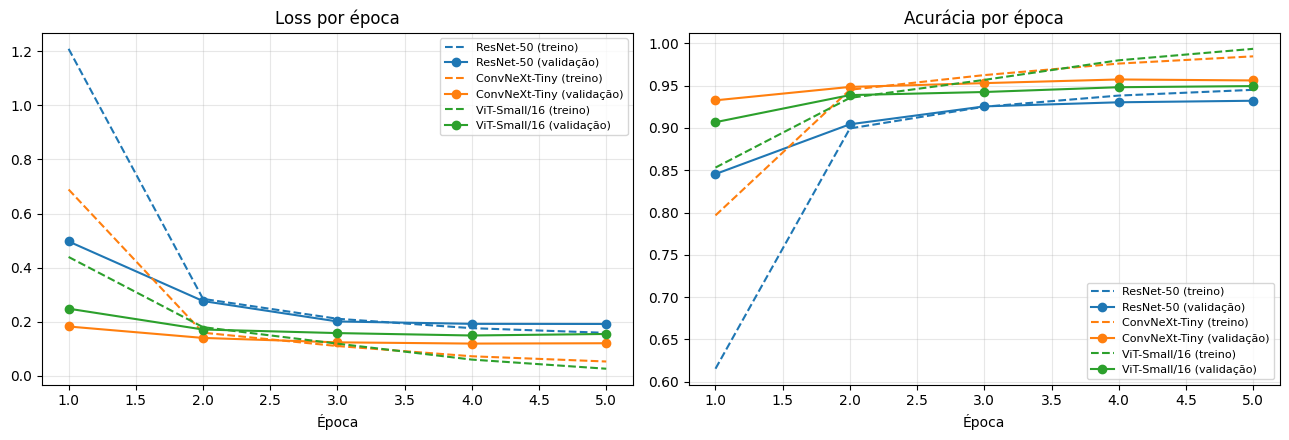

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for nome, h in historicos.items():
    ep = range(1, EPOCHS + 1)
    linha, = axes[0].plot(ep, h["train_loss"], "--", label=f"{nome} (treino)")
    axes[0].plot(ep, h["val_loss"], "-o", color=linha.get_color(), label=f"{nome} (validação)")
    axes[1].plot(ep, h["train_acc"], "--", color=linha.get_color(), label=f"{nome} (treino)")
    axes[1].plot(ep, h["val_acc"], "-o", color=linha.get_color(), label=f"{nome} (validação)")
axes[0].set_title("Loss por época")
axes[1].set_title("Acurácia por época")
for ax in axes:
    ax.set_xlabel("Época"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Avaliação no teste

Agora sim uso o conjunto de teste, uma vez só, para todos os modelos. O tempo de inferência é por imagem, rodando o teste inteiro (o baseline roda na CPU, as redes na GPU).

In [15]:
def linha(nome, params, tempo, acc_val, preds, t_inferencia):
    return {"Modelo": nome, "Parâmetros (M)": params, "Treino (min)": tempo, "Acc. validação": acc_val,
            "Acc. teste": (preds == y_test).mean(), "F1 macro (teste)": f1_score(y_test, preds, average="macro"),
            "Inferência (ms/img)": t_inferencia / len(y_test) * 1000}

t0 = time.time()
preds = baseline.predict(achatar(X_test))
params_baseline = (baseline.coef_.size + baseline.intercept_.size) / 1e6
linhas = [linha("Regressão Logística", params_baseline, tempo_baseline, acc_val_baseline, preds, time.time() - t0)]
preds_teste = {"Regressão Logística": preds}

for nome, modelo in modelos.items():
    t0 = time.time()
    _, _, preds = avaliar(modelo, test_loader)
    linhas.append(linha(nome, infos[nome]["params"], infos[nome]["tempo"], infos[nome]["val_acc"], preds, time.time() - t0))
    preds_teste[nome] = preds

tabela = pd.DataFrame(linhas).set_index("Modelo")
tabela.to_csv("resultados.csv")
tabela.round(4)

,Parâmetros (M),Treino (min),Acc. validação,Acc. teste,F1 macro (teste),Inferência (ms/img)
Modelo,,,,,,
Regressão Logística,0.0078,1.5819,0.8608,0.8425,0.8417,0.0039
ResNet-50,23.5285,5.6051,0.9322,0.9196,0.9197,0.4262
ConvNeXt-Tiny,27.8278,6.3597,0.9573,0.9543,0.9542,0.9417
ViT-Small/16,21.6131,3.7679,0.9495,0.9472,0.9471,0.2544


In [16]:
for nome, preds in preds_teste.items():
    print(f"=============== {nome} ===============")
    print(classification_report(y_test, preds, target_names=CLASSES, digits=4))

=============== Regressão Logística ===============
              precision    recall  f1-score   support

 T-shirt/top     0.7946    0.8010    0.7978      1000
     Trouser     0.9746    0.9580    0.9662      1000
    Pullover     0.7189    0.7340    0.7264      1000
       Dress     0.8314    0.8580    0.8445      1000
        Coat     0.7337    0.7550    0.7442      1000
      Sandal     0.9432    0.9300    0.9366      1000
       Shirt     0.6224    0.5670    0.5934      1000
     Sneaker     0.9167    0.9360    0.9263      1000
         Bag     0.9295    0.9360    0.9327      1000
  Ankle Boot     0.9481    0.9500    0.9491      1000

    accuracy                         0.8425     10000
   macro avg     0.8413    0.8425    0.8417     10000
weighted avg     0.8413    0.8425    0.8417     10000

=============== ResNet-50 ===============
              precision    recall  f1-score   support

 T-shirt/top     0.8831    0.8690    0.8760      1000
     Trouser     0.9929    0.9790    0

In [17]:
recall = pd.DataFrame({nome: confusion_matrix(y_test, p, normalize="true").diagonal() for nome, p in preds_teste.items()}, index=CLASSES)
recall.round(3)

,Regressão Logística,ResNet-50,ConvNeXt-Tiny,ViT-Small/16
T-shirt/top,0.801,0.869,0.904,0.902
Trouser,0.958,0.979,0.994,0.994
Pullover,0.734,0.873,0.931,0.928
Dress,0.858,0.914,0.968,0.946
Coat,0.755,0.890,0.950,0.930
Sandal,0.930,0.976,0.993,0.991
Shirt,0.567,0.768,0.849,0.825
Sneaker,0.936,0.980,0.982,0.986
Bag,0.936,0.993,0.994,0.998
Ankle Boot,0.950,0.954,0.978,0.972


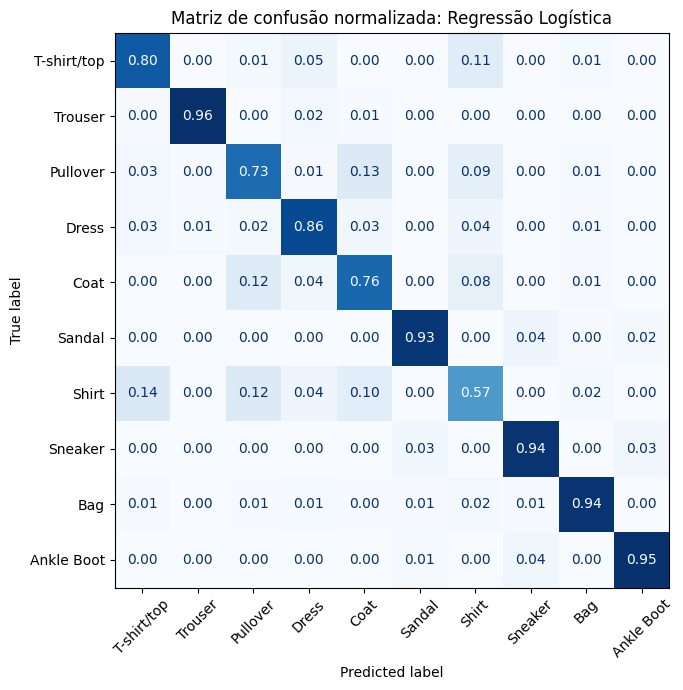

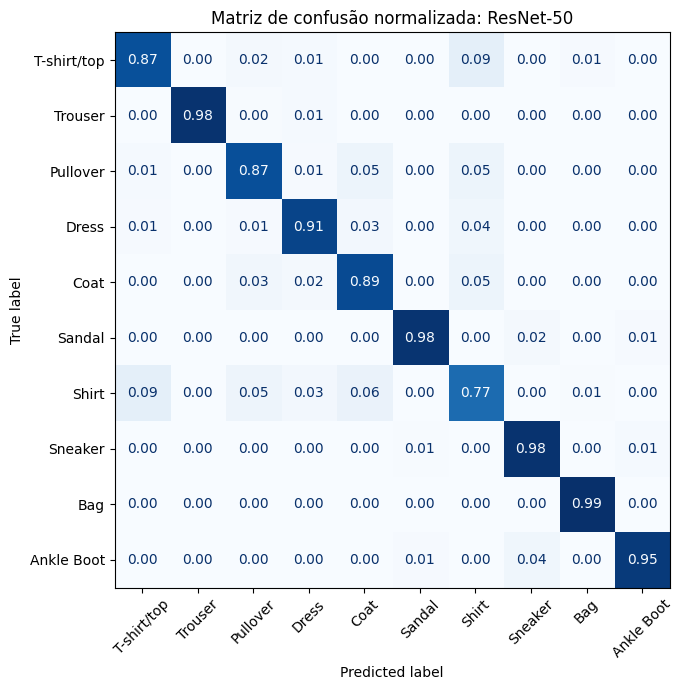

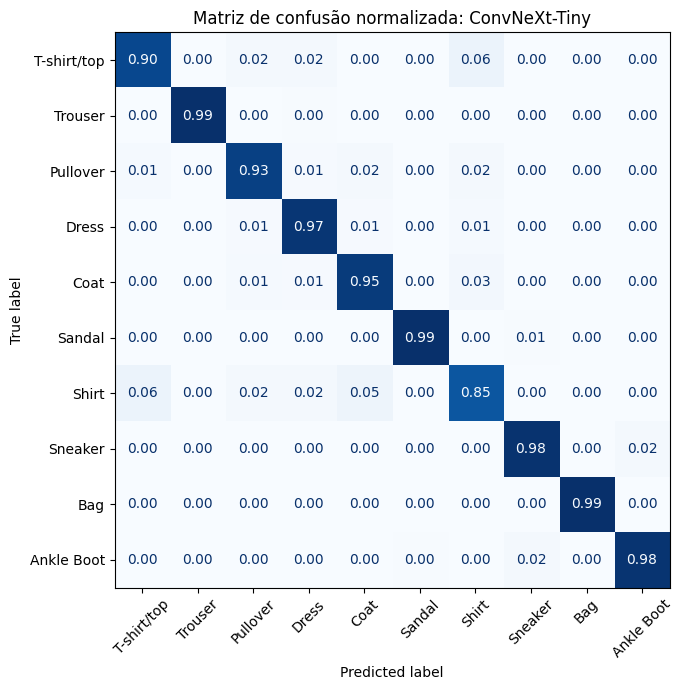

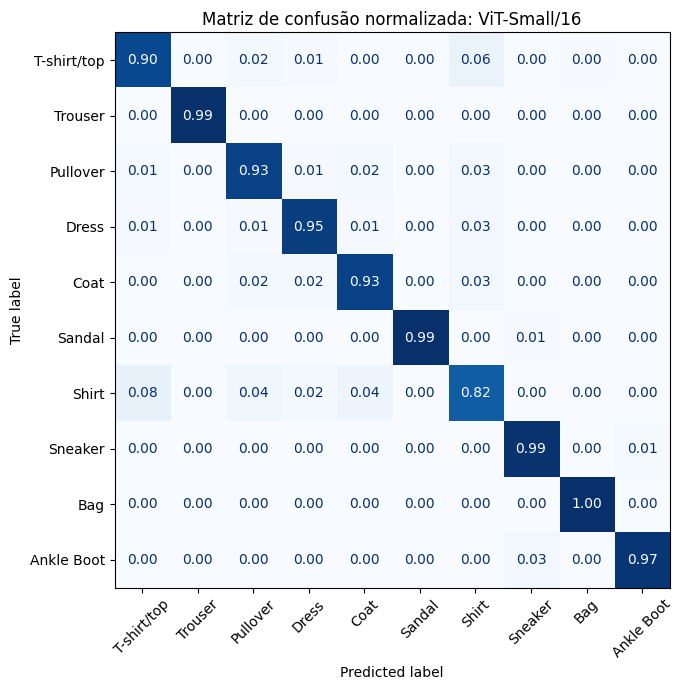

In [18]:
for nome, preds in preds_teste.items():
    fig, ax = plt.subplots(figsize=(8, 7))
    cm = confusion_matrix(y_test, preds, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False, xticks_rotation=45)
    ax.set_title(f"Matriz de confusão normalizada: {nome}")
    plt.tight_layout(); plt.show()

In [19]:
for nome, preds in preds_teste.items():
    cm = confusion_matrix(y_test, preds)
    np.fill_diagonal(cm, 0)
    print(nome)
    for i in np.argsort(cm, axis=None)[::-1][:5]:
        real, prev = divmod(i, 10)
        print(f"  {CLASSES[real]:12s} -> {CLASSES[prev]:12s}: {cm[real, prev]} erros")

Regressão Logística
  Shirt        -> T-shirt/top : 141 erros
  Pullover     -> Coat        : 126 erros
  Shirt        -> Pullover    : 125 erros
  Coat         -> Pullover    : 119 erros
  T-shirt/top  -> Shirt       : 111 erros
ResNet-50
  T-shirt/top  -> Shirt       : 90 erros
  Shirt        -> T-shirt/top : 90 erros
  Shirt        -> Coat        : 63 erros
  Coat         -> Shirt       : 53 erros
  Pullover     -> Coat        : 52 erros
ConvNeXt-Tiny
  Shirt        -> T-shirt/top : 62 erros
  T-shirt/top  -> Shirt       : 59 erros
  Shirt        -> Coat        : 50 erros
  Coat         -> Shirt       : 26 erros
  Pullover     -> Coat        : 23 erros
ViT-Small/16
  Shirt        -> T-shirt/top : 76 erros
  T-shirt/top  -> Shirt       : 63 erros
  Shirt        -> Coat        : 41 erros
  Shirt        -> Pullover    : 37 erros
  Coat         -> Shirt       : 31 erros


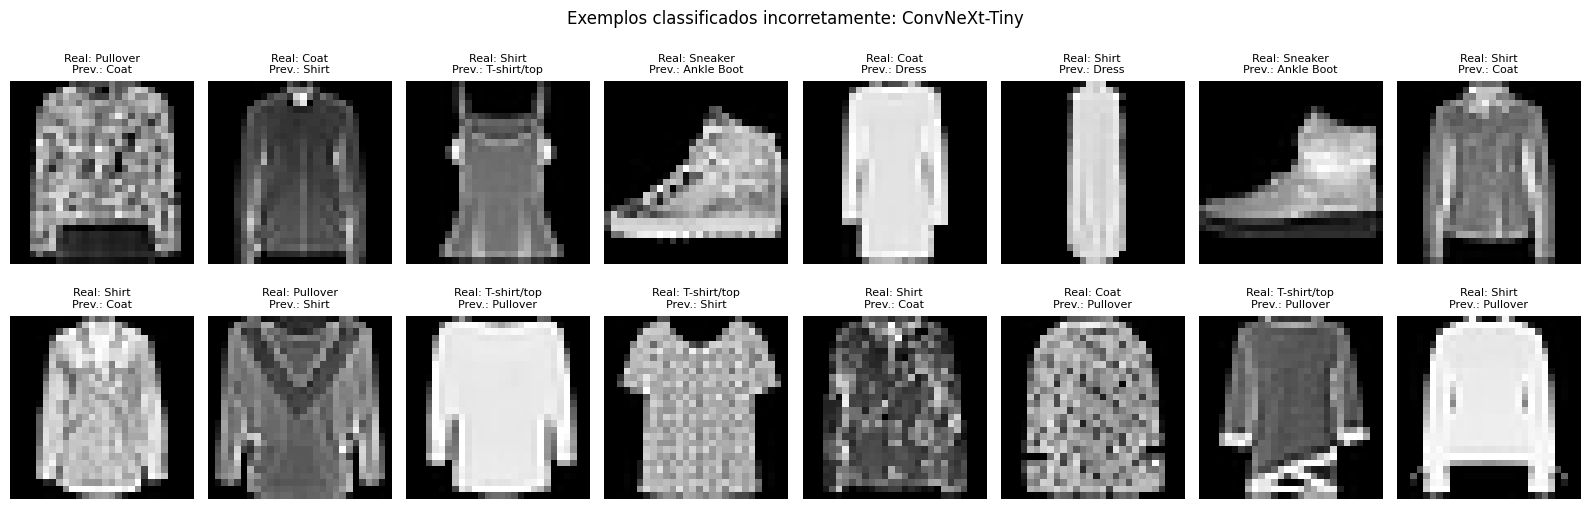

In [20]:
melhor = tabela["Acc. teste"].idxmax()
erros = np.where(preds_teste[melhor] != y_test)[0]
amostra = np.random.default_rng(SEED).choice(erros, min(16, len(erros)), replace=False)

fig, axes = plt.subplots(2, 8, figsize=(16, 5.5))
for ax, i in zip(axes.flat, amostra):
    ax.imshow(X_test[i], cmap="gray")
    ax.set_title(f"Real: {CLASSES[y_test[i]]}\nPrev.: {CLASSES[preds_teste[melhor][i]]}", fontsize=8)
    ax.axis("off")
fig.suptitle(f"Exemplos classificados incorretamente: {melhor}")
plt.tight_layout(); plt.show()